# 07 · Evaluating with probabilities: metrics, the selection metric and the scoreboard

Until now every run reported one number, accuracy, on 5 folds. This notebook changes how every model is judged:
1. the pipeline keeps **out-of-fold probabilities**, not just yes/no predictions, and reports **several metrics** from them;
2. what each metric rewards, and which threshold-free metrics don't depend on the 0.5 cut-off;
3. one **selection metric** that tuning maximises, and why it matters which one;
4. **`class_weight`**: what it does to recall, precision and the fairness check;
5. **comparing two models** with the corrected paired t-test;
6. the **scoreboard**: every run kept, comparable, and compared;
7. a worked example of **feature selection** (the first challenge);
8. a note on regression.

It ends with the pipeline changes, the README task and the challenges.

<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">
📝 <b>Feedback on the course so far</b> (anonymous, about 3 minutes): <a href="https://forms.gle/ztjiyG9f5F6iDCqH8">https://forms.gle/ztjiyG9f5F6iDCqH8</a>
</div>

## 1 · Setup

In [1]:
import copy
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import yaml
from category_encoders import CountEncoder
from scipy import stats
from sklearn.base import BaseEstimator, clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier, GradientBoostingRegressor,
    HistGradientBoostingClassifier, RandomForestClassifier,
)
from sklearn.feature_selection import SelectorMixin
from sklearn.impute import SimpleImputer
from sklearn.linear_model import BayesianRidge, LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, classification_report, confusion_matrix, fbeta_score,
    get_scorer, make_scorer, mean_absolute_error, mean_squared_error, precision_recall_curve, r2_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, TargetEncoder, StandardScaler, MinMaxScaler, RobustScaler,
)
from sklearn.random_projection import SparseRandomProjection
from sklearn.tree import DecisionTreeClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
PIPELINE_DIR = Path.cwd()
while not (PIPELINE_DIR / "data" / "compas_two_year_recidivism.csv").is_file():
    if PIPELINE_DIR.parent == PIPELINE_DIR:
        raise FileNotFoundError("Could not find data/compas_two_year_recidivism.csv in the current directory or its parents.")
    PIPELINE_DIR = PIPELINE_DIR.parent
RUN_NESTED = False                             # True: recompute the nested CV of section 6 (about 8 minutes)

c:\Users\mdz\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The parts of `config.yaml` this notebook uses, written out so the notebook runs on its own. The `cv` section is new:

In [2]:
CONFIG_YAML = """
data:
  path: "data/compas_two_year_recidivism.csv"
  target: "two_year_recid"
  sensitive_attr: "race"                            # never a feature; used only for the fairness report
  drop_columns: ["id", "decile_score", "score_text"]  # kept in the data, never used as features

# Locked test set: never used to fit, tune or choose anything. Do not change once set.
test_set:
  size: 0.2
  random_state: 42

cv:
  n_splits: 5
  shuffle: true
  random_state: 42
  # Reported for every run. fbeta_<beta> weights recall beta times as much as precision.
  metrics: ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "fbeta_2", "roc_auc", "average_precision"]
  selection_metric: "roc_auc"                       # one of metrics: what tuning maximises and runs are ranked by
  n_jobs: 1                                         # -1 = all CPU cores

diagnostics:
  id_column: "id"
  numeric_text_columns: ["priors_count", "prior_offenses"]
  # "nan" catches real NaNs turned into text by the category cleanup.
  placeholder_tokens: ["-", "?", "n/a", "N/A", "na", "NA", "", "nan"]
  validity_rules:
    age: {min: 18, max: 100}
    decile_score: {min: 1, max: 10}
    juv_fel_count: {min: 0}
    priors_count: {min: 0, max: 60}
  canonical_categories:
    sex:
      male: "Male"
      female: "Female"
    race:
      african-american: "African-American"
      african american: "African-American"
      caucasian: "Caucasian"
      hispanic: "Hispanic"
      other: "Other"
      asian: "Asian"
      native american: "Native American"
    c_charge_degree:
      f: "F"
      felony: "F"
      m: "M"
      misdemeanor: "M"
    score_text:
      low: "Low"
      medium: "Medium"
      high: "High"
  redundant_columns: ["prior_offenses", "age_in_months", "juvenile_total"]

preprocessing:
  encoder: "target"                                 # onehot | ordinal | count | target
  scaler: "robust"                                  # none | standard | minmax | robust
  numeric_features: ["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"]
  categorical_features: ["sex", "age_cat", "c_charge_degree"]
  mnar_indicator_sources: ["priors_count", "c_charge_degree"]   # get a <col>_was_missing flag
  random_state: 42                                  # target encoder's internal folds
  imputation:
    numeric_strategy: "median"
    categorical_strategy: "most_frequent"

model:
  type: "gradient_boosting"  # dummy | logistic_regression | naive_bayes | decision_tree | random_forest | oblique_random_forest | adaboost | gradient_boosting | hist_gradient_boosting
  params:
    random_state: 42
  # Other models' params, to swap in. class_weight "balanced" weights each class by 1 / its frequency
  # (GradientBoostingClassifier and GaussianNB have no class_weight).
  # logistic_regression:    {max_iter: 2000, class_weight: balanced}
  # naive_bayes:            {}
  # decision_tree:          {random_state: 42, class_weight: balanced}
  # random_forest:          {n_estimators: 200, random_state: 42, n_jobs: -1, class_weight: balanced}
  # oblique_random_forest:  {n_estimators: 200, n_components: 10, random_state: 42, n_jobs: -1}
  # adaboost:               {max_depth: 1, n_estimators: 200, learning_rate: 1.0, random_state: 42}
  # hist_gradient_boosting: {random_state: 42, class_weight: balanced}

tuning:
  enabled: true
  n_trials: 30
  n_splits: 5                                       # folds that score each candidate
  random_state: 42                                  # seeds the sampler and those folds
  # Keys are Pipeline parameter names. Types: int / float (low, high, log) or categorical (choices).
  # Ensembles take minutes per run: use a small n_trials while testing.
  search_spaces:
    decision_tree:
      model__max_depth: {type: int, low: 1, high: 20}
      model__min_samples_leaf: {type: int, low: 1, high: 200, log: true}
      model__criterion: {type: categorical, choices: ["gini", "entropy"]}
"""
config = yaml.safe_load(CONFIG_YAML)

In [3]:
print("cv:", config["cv"])

cv: {'n_splits': 5, 'shuffle': True, 'random_state': 42, 'metrics': ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'fbeta_2', 'roc_auc', 'average_precision'], 'selection_metric': 'roc_auc', 'n_jobs': 1}


The pipeline functions from earlier weeks, **unchanged** (`src/preprocessing.py`, `src/model.py`, `src/evaluate.py`), including the models added in `06_boosting`:

In [4]:
def flag_invalid_values(df: pd.DataFrame, rules: dict) -> pd.DataFrame:
    """
    Applies {column: {"min": ..., "max": ...}} domain rules (either bound optional) and sets
    violations to NaN, in place. Returns the number of violations per column.
    """
    report_rows = []
    for column, bounds in rules.items():
        if column not in df.columns:
            continue
        numeric = pd.to_numeric(df[column], errors="coerce")
        lower_ok = numeric >= bounds["min"] if "min" in bounds else pd.Series(True, index=numeric.index)
        upper_ok = numeric <= bounds["max"] if "max" in bounds else pd.Series(True, index=numeric.index)
        violations = numeric.notna() & ~(lower_ok & upper_ok)
        report_rows.append({"column": column, "rule": bounds, "violations": int(violations.sum())})
        df.loc[violations, column] = np.nan
    return pd.DataFrame(report_rows)


def _canonicalize_categories(df: pd.DataFrame, columns_and_maps: dict, placeholder_tokens: set) -> pd.DataFrame:
    out = df.copy()
    for col, mapping in columns_and_maps.items():
        if col not in out.columns:
            continue
        cleaned = out[col].astype(str).str.strip()
        lowered = cleaned.str.lower()
        out[col] = lowered.map(mapping).fillna(cleaned)
        out.loc[out[col].astype(str).str.strip().isin(placeholder_tokens), col] = np.nan
    return out


def clean_dataset(df: pd.DataFrame, diagnostics_config: dict) -> pd.DataFrame:
    """
    Applies the cleaning rules in `diagnostics_config`: placeholder tokens and domain-rule
    violations become NaN, category spellings are canonicalized and redundant columns are
    dropped. Row-preserving and target-agnostic, so it runs unchanged on data to predict.
    """
    out = df.copy()
    placeholder_tokens = set(diagnostics_config.get("placeholder_tokens", []))

    for col in diagnostics_config.get("numeric_text_columns", []):
        if col in out.columns:
            out[col] = pd.to_numeric(out[col].replace(list(placeholder_tokens), np.nan), errors="coerce")

    flag_invalid_values(out, diagnostics_config.get("validity_rules", {}))
    out = _canonicalize_categories(out, diagnostics_config.get("canonical_categories", {}), placeholder_tokens)

    columns_to_drop = [c for c in diagnostics_config.get("redundant_columns", []) if c in out.columns]
    return out.drop(columns=columns_to_drop)


def drop_duplicate_rows(df: pd.DataFrame, id_column: str = None) -> pd.DataFrame:
    """
    Training data only, before `split_dev_test`: drops exact duplicate rows and repeated ids
    (keeping the first). Never call it on data to predict: every row needs a prediction.
    """
    out = df.drop_duplicates()
    if id_column and id_column in out.columns:
        out = out.drop_duplicates(subset=id_column, keep="first")
    return out


def add_missingness_indicators(df: pd.DataFrame, mnar_indicator_sources: list) -> pd.DataFrame:
    """Adds a `<col>_was_missing` flag for each listed column, before it is imputed."""
    out = df.copy()
    for col in mnar_indicator_sources:
        if col in out.columns:
            out[f"{col}_was_missing"] = out[col].isna().astype(int)
    return out


def split_features_target(df: pd.DataFrame, data_config: dict, mnar_indicator_sources: list):
    """
    Returns (X, y, extras). `extras` holds the columns kept out of the features for auditing
    (the sensitive attribute and COMPAS's own score). On label-free data `y` is None.
    """
    target = data_config["target"]
    sensitive_attr = data_config["sensitive_attr"]
    drop_columns = data_config.get("drop_columns", [])

    df = add_missingness_indicators(df, mnar_indicator_sources)
    y = df[target] if target in df.columns else None

    extras_cols = [c for c in [sensitive_attr, "score_text"] if c in df.columns]
    extras = df[extras_cols].copy() if extras_cols else None

    always_drop = set(drop_columns) | {target, sensitive_attr}
    feature_cols = [c for c in df.columns if c not in always_drop]
    return df[feature_cols], y, extras


_SCALERS = {"none": "passthrough", "standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}


# sklearn's TargetEncoder cross-fits: a training row's encoding never uses its own label.
_ENCODERS = {
    "onehot": lambda seed: OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "ordinal": lambda seed: OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "count": lambda seed: CountEncoder(handle_unknown=0, handle_missing=0),
    "target": lambda seed: TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=seed)),
}


def build_preprocessor(preprocessing_config: dict) -> ColumnTransformer:
    """
    Builds the unfitted ColumnTransformer described by `preprocessing_config`: imputation and
    scaling for numeric columns, imputation and encoding for categorical ones, and the
    missingness flags passed through. Every encoder tolerates unseen categories.
    """
    imputation = preprocessing_config.get("imputation", {})
    scaler_factory = _SCALERS[preprocessing_config["scaler"]]
    scaler = scaler_factory() if callable(scaler_factory) else scaler_factory
    encoder = _ENCODERS[preprocessing_config["encoder"]](preprocessing_config.get("random_state"))

    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy=imputation.get("numeric_strategy", "median"))),
        ("scale", scaler),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy=imputation.get("categorical_strategy", "most_frequent"))),
        ("encode", encoder),
    ])
    indicator_cols = [f"{c}_was_missing" for c in preprocessing_config.get("mnar_indicator_sources", [])]

    return ColumnTransformer([
        ("numeric", numeric_pipeline, preprocessing_config["numeric_features"]),
        ("categorical", categorical_pipeline, preprocessing_config["categorical_features"]),
        ("indicators", "passthrough", indicator_cols),
    ])


def split_dev_test(X, y, extras, test_size: float, random_state: int):
    """
    Stratified split into a development set, used for every decision, and a locked test set,
    used only for the final assessment. Returns X_dev, X_test, y_dev, y_test, extras_dev,
    extras_test, row-aligned.
    """
    return train_test_split(X, y, extras, test_size=test_size, random_state=random_state, stratify=y)


def adaboost(max_depth: int = 1, **params):
    """
    AdaBoost over decision trees of depth `max_depth` (1 = stumps); `params` go to
    AdaBoostClassifier. The trees' depth is tuned as `model__estimator__max_depth`.
    """
    return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=max_depth), **params)


def oblique_random_forest(n_estimators: int = 100, n_components: int = 10, density="auto",
                          random_state=None, n_jobs=None, **tree_params):
    """
    A forest of oblique trees: each tree is fit on a bootstrap sample, on `n_components`
    random sparse linear combinations of the features (a new set per tree), so its splits are
    hyperplanes. `tree_params` go to every tree (`max_features` defaults to "sqrt"). Tuned as
    `model__estimator__tree__<param>` and `model__estimator__project__<param>`.
    """
    tree_params.setdefault("max_features", "sqrt")
    oblique_tree = Pipeline([
        ("project", SparseRandomProjection(n_components=n_components, density=density)),
        ("tree", DecisionTreeClassifier(**tree_params)),
    ])
    return BaggingClassifier(estimator=oblique_tree, n_estimators=n_estimators,
                             random_state=random_state, n_jobs=n_jobs)


_MODELS = {
    "dummy": DummyClassifier,
    "logistic_regression": LogisticRegression,
    "decision_tree": DecisionTreeClassifier,
    "random_forest": RandomForestClassifier,
    "oblique_random_forest": oblique_random_forest,
    "adaboost": adaboost,
    "gradient_boosting": GradientBoostingClassifier,
    "hist_gradient_boosting": HistGradientBoostingClassifier,
    "naive_bayes": GaussianNB,
}


def build_model(model_config: dict):
    """Builds the model named by `model_config["type"]` with `model_config["params"]`."""
    model_type = model_config["type"]
    params = model_config.get("params") or {}

    if model_type not in _MODELS:
        raise ValueError(f"Unknown model type: {model_type}. Options: {list(_MODELS)}")

    return _MODELS[model_type](**params)


def build_pipeline(preprocessing_config: dict, model_config: dict) -> Pipeline:
    """
    The estimator that is cross-validated, tuned and refit: preprocessing and model as one
    Pipeline, so every learned step is re-fit on the training part of each fold. Step names
    address hyperparameters from outside (`model__max_depth`, `prep__numeric__impute__strategy`).
    Any new learned step (e.g. feature selection) belongs here, between "prep" and "model".
    """
    return Pipeline([
        ("prep", build_preprocessor(preprocessing_config)),
        ("model", build_model(model_config)),
    ])


def corrected_paired_test(scores_a, scores_b, test_train_ratio: float) -> dict:
    """
    Corrected paired t-test (Nadeau & Bengio, 2003) for two models scored on the same CV folds.
    Folds share most of their training rows, so their scores are correlated and the plain
    t-test is overconfident; the variance of the differences is inflated by `test_train_ratio`
    (validation rows / training rows per fold: 1 / (k - 1) for k-fold).

    Returns the mean difference (a - b), the folds where a scores higher, t and the two-sided
    p-value.
    """
    diff = np.asarray(scores_a, dtype=float) - np.asarray(scores_b, dtype=float)
    k = len(diff)
    se = np.sqrt((1 / k + test_train_ratio) * diff.var(ddof=1))
    t = float(diff.mean() / se) if se > 0 else 0.0
    p_value = float(2 * stats.t.sf(abs(t), df=k - 1))
    return {"mean_diff": float(diff.mean()), "wins": f"{int((diff > 0).sum())}/{k}", "t": t, "p_value": p_value}

In [5]:
data_path = Path(config["data"]["path"])
if not data_path.is_absolute():
    for data_root in (Path.cwd(), *Path.cwd().parents):
        candidate = data_root / data_path
        if candidate.is_file():
            data_path = candidate
            break
    else:
        raise FileNotFoundError(f"Could not find {config['data']['path']!r} from {Path.cwd()} or its parent directories.")
df_raw = pd.read_csv(data_path)
df_clean = clean_dataset(df_raw, config["diagnostics"])
df_clean = drop_duplicate_rows(df_clean, config["diagnostics"].get("id_column"))
X, y, extras = split_features_target(df_clean, config["data"], config["preprocessing"]["mnar_indicator_sources"])
X_dev, X_test, y_dev, y_test, extras_dev, extras_test = split_dev_test(
    X, y, extras, test_size=config["test_set"]["size"], random_state=config["test_set"]["random_state"])
print(f"development set: {len(X_dev)} rows (base rate {y_dev.mean():.3f}) · locked test set: {len(X_test)} rows")

FileNotFoundError: [Errno 2] No such file or directory: '..\\baseline-pipeline\\data\\compas_two_year_recidivism.csv'

## 2 · Out-of-fold probabilities, scored on several metrics

**Out-of-fold probabilities.** Every row is in exactly one validation fold, so every row gets one probability of reoffending, predicted by the fold model that did *not* train on it. By hand, on the pipeline's 5 folds:

In [ ]:
cv = StratifiedKFold(n_splits=config["cv"]["n_splits"], shuffle=config["cv"]["shuffle"],
                     random_state=config["cv"]["random_state"])
pipeline = build_pipeline(config["preprocessing"], config["model"])     # gradient boosting, config params

oof_proba_by_hand = np.empty(len(X_dev))
for train_idx, val_idx in cv.split(X_dev, y_dev):
    model = clone(pipeline).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    oof_proba_by_hand[val_idx] = model.predict_proba(X_dev.iloc[val_idx])[:, 1]
print("first 5 out-of-fold probabilities:", np.round(oof_proba_by_hand[:5], 3))

first 5 out-of-fold probabilities: [0.483 0.194 0.352 0.189 0.198]


Several metrics need **scorers**: scikit-learn names most of them (`"roc_auc"`, `"f1"`, …). F-beta needs its `beta`, so `fbeta_<beta>` names are built with `make_scorer`:

<div style="background-color:#e8f5e9; border-left:6px solid #2e7d32; padding:10px 14px; border-radius:4px"> <b>New in the pipeline: <code>build_scorers()</code></b> &nbsp;·&nbsp; <code>src/evaluate.py</code><br>One scorer per metric listed in <code>cv.metrics</code>.</div>

In [ ]:
def build_scorers(metrics: list) -> dict:
    """
    {name: scorer} for scikit-learn metric names (`accuracy`, `roc_auc`, ...), plus `fbeta_<beta>`
    (e.g. `fbeta_2`: recall weighted twice as much as precision).
    """
    scorers = {}
    for name in metrics:
        if name.startswith("fbeta_"):
            scorers[name] = make_scorer(fbeta_score, beta=float(name.split("_", 1)[1]), zero_division=0)
        else:
            scorers[name] = get_scorer(name)
    return scorers

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"> <b>Changed in the pipeline: <code>cross_validate_pipeline()</code></b> &nbsp;·&nbsp; <code>src/evaluate.py</code><br>Now scores every metric, reports train/validation/gap for the selection metric, and returns out-of-fold <b>probabilities</b> instead of labels.</div>

In [ ]:
def cross_validate_pipeline(pipeline, X, y, cv, scorers: dict, selection_metric: str, n_jobs: int = 1):
    """
    Fits a fresh copy of `pipeline` (preprocessing included) on each fold's training part and
    scores it on that fold's validation part, on every metric in `scorers`.

    Returns (fold_scores, oof_proba):
      - fold_scores: one row per fold with the validation score of every metric, plus the
        train score and train-validation gap of `selection_metric`;
      - oof_proba: out-of-fold probability of the positive class for every row, from the
        fold model that did not train on it. `cv` must be a partition (each row validated
        exactly once).
    """
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=scorers, return_train_score=True,
                            return_estimator=True, return_indices=True, n_jobs=n_jobs)
    fold_scores = pd.DataFrame({"fold": range(1, cv.get_n_splits() + 1)})
    fold_scores["train"] = scores[f"train_{selection_metric}"]
    fold_scores["validation"] = scores[f"test_{selection_metric}"]
    fold_scores["gap"] = fold_scores["train"] - fold_scores["validation"]
    for name in scorers:
        fold_scores[name] = scores[f"test_{name}"]

    oof_proba = np.empty(len(X))
    for model, val_idx in zip(scores["estimator"], scores["indices"]["test"]):
        oof_proba[val_idx] = model.predict_proba(X.iloc[val_idx])[:, 1]
    return fold_scores, oof_proba

In [ ]:
scorers = build_scorers(config["cv"]["metrics"])
selection_metric = config["cv"]["selection_metric"]
fold_scores, oof_proba = cross_validate_pipeline(pipeline, X_dev, y_dev, cv, scorers, selection_metric)
print("largest difference from the by-hand probabilities:", np.abs(oof_proba - oof_proba_by_hand).max())
fold_scores.round(3)

largest difference from the by-hand probabilities: 0.0


,fold,train,validation,gap,accuracy,balanced_accuracy,precision,recall,f1,fbeta_2,roc_auc,average_precision
0,1,0.747,0.731,0.016,0.672,0.658,0.679,0.516,0.587,0.542,0.731,0.685
1,2,0.755,0.701,0.054,0.664,0.655,0.645,0.563,0.602,0.578,0.701,0.652
2,3,0.748,0.735,0.013,0.696,0.687,0.687,0.596,0.639,0.612,0.735,0.700
3,4,0.745,0.737,0.008,0.689,0.675,0.702,0.538,0.609,0.565,0.737,0.726
4,5,0.748,0.730,0.019,0.678,0.665,0.681,0.535,0.599,0.559,0.730,0.679


<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"> <b>Changed in the pipeline: <code>cv_report()</code></b> &nbsp;·&nbsp; <code>src/evaluate.py</code><br>The per-fold table and the mean and std of every metric, for the results file (it no longer prints).</div>

In [ ]:
def cv_report(fold_scores: pd.DataFrame, metrics: list, selection_metric: str, title: str) -> str:
    """Per-fold table and the mean and std of every metric, as text."""
    lines = [
        f"{title} ({len(fold_scores)} stratified folds, selection metric: {selection_metric})",
        "",
        fold_scores.to_string(index=False, float_format=lambda v: f"{v:.3f}"),
        "",
        fold_scores[metrics].agg(["mean", "std"]).T.to_string(float_format=lambda v: f"{v:.3f}"),
        f"\n{selection_metric}: train-validation gap mean = {fold_scores['gap'].mean():+.3f}",
    ]
    return "\n".join(lines)

In [ ]:
metrics = config["cv"]["metrics"]
fold_scores[metrics].agg(["mean", "std"]).T.round(3)     # what the console prints

,mean,std
accuracy,0.680,0.013
balanced_accuracy,0.668,0.013
precision,0.679,0.021
recall,0.550,0.031
f1,0.607,0.019
fbeta_2,0.571,0.026
roc_auc,0.727,0.015
average_precision,0.688,0.027


## 3 · What each metric rewards

Every threshold-dependent metric comes from the **confusion matrix** at one threshold (0.5: predicted to reoffend if p ≥ 0.5). From the out-of-fold probabilities, pooled over all rows:

![metrics](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTdlmN9dvXooiYfYR6vpOWdZOj13wO10yd3gebGxuibbRw011r6HkMCB4xL&s=10g)

In [ ]:
y_pred = (oof_proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_dev, y_pred).ravel()
precision, recall, specificity = tp / (tp + fp), tp / (tp + fn), tn / (tn + fp)
by_hand = {
    "accuracy           (tp + tn) / n": (tp + tn) / len(y_dev),
    "precision          tp / (tp + fp)   of those flagged, share who reoffended": precision,
    "recall             tp / (tp + fn)   of those who reoffended, share flagged": recall,
    "specificity        tn / (tn + fp)   of those who did not, share not flagged": specificity,
    "balanced_accuracy  (recall + specificity) / 2": (recall + specificity) / 2,
    "f1                 harmonic mean of precision and recall": 2 * precision * recall / (precision + recall),
    "fbeta_2            recall counts 2x as much": 5 * precision * recall / (4 * precision + recall),
}
print(pd.DataFrame(confusion_matrix(y_dev, y_pred), index=["true 0", "true 1"], columns=["predicted 0", "predicted 1"]), "\n")
for name, value in by_hand.items():
    print(f"{value:.3f}  {name}")

        predicted 0  predicted 1
true 0         2492          678
true 1         1171         1430 

0.680  accuracy           (tp + tn) / n
0.678  precision          tp / (tp + fp)   of those flagged, share who reoffended
0.550  recall             tp / (tp + fn)   of those who reoffended, share flagged
0.786  specificity        tn / (tn + fp)   of those who did not, share not flagged
0.668  balanced_accuracy  (recall + specificity) / 2
0.607  f1                 harmonic mean of precision and recall
0.571  fbeta_2            recall counts 2x as much


The **threshold** is a choice, and it moves all of these. ROC-AUC and average precision (PR-AUC) don't move: they score the **ranking** of the probabilities over every threshold at once.

In [ ]:
rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (oof_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, pred).ravel()
    rows.append({"threshold": threshold, "share flagged": pred.mean(), "precision": tp / (tp + fp),
                 "recall": tp / (tp + fn), "balanced_accuracy": (tp / (tp + fn) + tn / (tn + fp)) / 2,
                 "f1": 2 * tp / (2 * tp + fp + fn), "fbeta_2": fbeta_score(y_dev, pred, beta=2),
                 "roc_auc": roc_auc_score(y_dev, oof_proba)})
pd.DataFrame(rows).round(3)

,threshold,share flagged,precision,recall,balanced_accuracy,f1,fbeta_2,roc_auc
0,0.3,0.687,0.548,0.836,0.636,0.662,0.757,0.725
1,0.4,0.505,0.616,0.689,0.668,0.650,0.673,0.725
2,0.5,0.365,0.678,0.550,0.668,0.607,0.571,0.725
3,0.6,0.276,0.714,0.438,0.647,0.543,0.474,0.725
4,0.7,0.154,0.790,0.270,0.605,0.402,0.310,0.725


**ROC-AUC** is the probability that a random reoffender gets a higher score than a random non-reoffender (0.5 = coin flip). **Average precision** summarises the precision–recall curve; its floor is the base rate (0.45), not 0.5. Both can score any risk score on the same rows, including COMPAS's own 1–10 decile score, which was never a model feature:

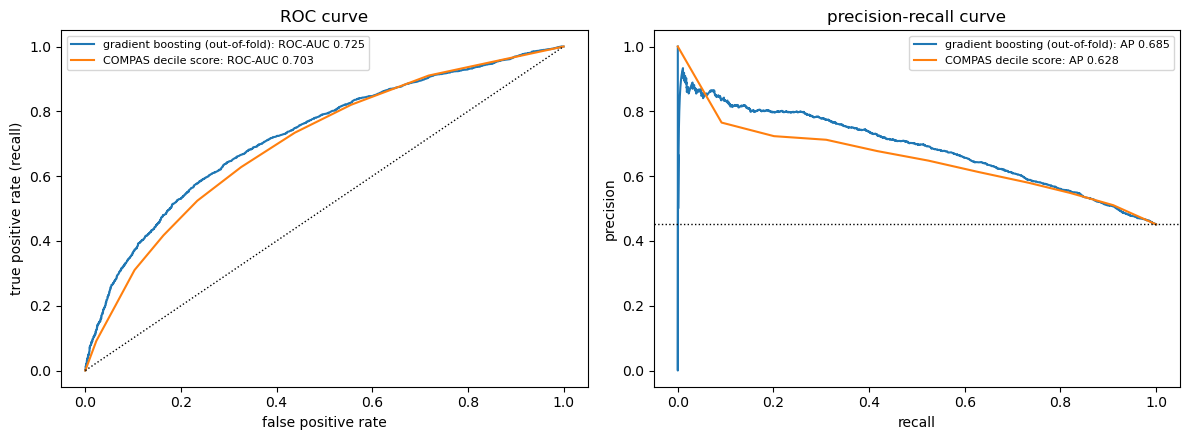

COMPAS decile score known for 99.9% of development rows


In [ ]:
decile = df_clean.loc[X_dev.index, "decile_score"]
known = decile.notna().to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, score, mask in [("gradient boosting (out-of-fold)", oof_proba, np.ones(len(y_dev), bool)),
                           ("COMPAS decile score", decile.to_numpy(), known)]:
    fpr, tpr, _ = roc_curve(y_dev[mask], score[mask])
    prec, rec, _ = precision_recall_curve(y_dev[mask], score[mask])
    axes[0].plot(fpr, tpr, label=f"{label}: ROC-AUC {roc_auc_score(y_dev[mask], score[mask]):.3f}")
    axes[1].plot(rec, prec, label=f"{label}: AP {average_precision_score(y_dev[mask], score[mask]):.3f}")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[1].axhline(y_dev.mean(), color="k", ls=":", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve")
axes[1].set(xlabel="recall", ylabel="precision", title="precision-recall curve")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"COMPAS decile score known for {known.mean():.1%} of development rows")

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"> <b>Changed in the pipeline: <code>oof_classification_report()</code></b> &nbsp;·&nbsp; <code>src/evaluate.py</code><br>Takes the out-of-fold probabilities and a threshold, and adds the confusion matrix.</div>

In [ ]:
def oof_classification_report(y_true, oof_proba, threshold: float = 0.5) -> str:
    """Confusion matrix and classification report of the out-of-fold predictions, as text."""
    y_pred = (oof_proba >= threshold).astype(int)
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred), index=["true 0", "true 1"],
                      columns=["predicted 0", "predicted 1"])
    return (f"Out-of-fold predictions, development set (threshold {threshold}):\n\n"
            f"{cm.to_string()}\n\n{classification_report(y_true, y_pred, zero_division=0)}")

In [ ]:
print(oof_classification_report(y_dev, oof_proba))

Out-of-fold predictions, development set (threshold 0.5):

        predicted 0  predicted 1
true 0         2492          678
true 1         1171         1430

              precision    recall  f1-score   support

           0       0.68      0.79      0.73      3170
           1       0.68      0.55      0.61      2601

    accuracy                           0.68      5771
   macro avg       0.68      0.67      0.67      5771
weighted avg       0.68      0.68      0.67      5771



## 4 · The selection metric

The pipeline reports eight metrics but **optimises one**: `cv.selection_metric`. It's what Optuna maximises and what runs are ranked by. Different metrics ask for different models. Tuning the decision tree three times, each time on a different metric:

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"> <b>Changed in the pipeline: <code>tune_pipeline()</code></b> &nbsp;·&nbsp; <code>src/tuning.py</code><br>Same search; it now takes a <code>scorer</code> (the selection metric's) instead of a metric name.</div>

In [ ]:
def tune_pipeline(pipeline, X, y, cv, scorer, search_space: dict, n_trials: int,
                  random_state: int, n_jobs: int = 1):
    """
    Runs an Optuna study (seeded TPE sampler) on (X, y). Each trial draws one value per entry
    of `search_space` (`type`: int / float / categorical; keys are Pipeline parameter names,
    e.g. `model__max_depth`), sets them on a fresh copy of `pipeline`, and returns its mean
    CV score over `cv` with `scorer` (the selection metric).

    Returns (best_pipeline, study): an unfitted copy of `pipeline` with the best trial's
    hyperparameters, and the study with every trial (mean score and fold std).
    """
    def objective(trial):
        params = {}
        for name, spec in search_space.items():
            if spec["type"] == "int":
                params[name] = trial.suggest_int(name, spec["low"], spec["high"], log=spec.get("log", False))
            elif spec["type"] == "float":
                params[name] = trial.suggest_float(name, spec["low"], spec["high"], log=spec.get("log", False))
            elif spec["type"] == "categorical":
                params[name] = trial.suggest_categorical(name, spec["choices"])
            else:
                raise ValueError(f"Unknown search-space type for {name}: {spec['type']}. "
                                 "Options: int, float, categorical")
        candidate = clone(pipeline).set_params(**params)
        scores = cross_val_score(candidate, X, y, cv=cv, scoring=scorer, n_jobs=n_jobs)
        trial.set_user_attr("std", float(scores.std(ddof=1)))
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=random_state))
    study.optimize(objective, n_trials=n_trials)
    best_pipeline = clone(pipeline).set_params(**study.best_params)
    return best_pipeline, study

In [ ]:
inner_cv = StratifiedKFold(n_splits=config["tuning"]["n_splits"], shuffle=True, random_state=config["tuning"]["random_state"])
tree = build_pipeline(config["preprocessing"], {"type": "decision_tree", "params": {"random_state": 42}})
space = config["tuning"]["search_spaces"]["decision_tree"]

rows = []
for metric in ["accuracy", "fbeta_2", "roc_auc"]:
    best, study = tune_pipeline(tree, X_dev, y_dev, inner_cv, scorers[metric], space, n_trials=20,
                                random_state=config["tuning"]["random_state"])
    scores, _ = cross_validate_pipeline(best, X_dev, y_dev, cv, scorers, metric)
    rows.append({"tuned on": metric, **{k.replace("model__", ""): v for k, v in study.best_params.items()},
                 **scores[metrics].mean().to_dict()})
pd.DataFrame(rows).set_index("tuned on").round(3).T

tuned on,accuracy,fbeta_2,roc_auc
max_depth,9,2,12
min_samples_leaf,101,148,107
criterion,gini,gini,gini
accuracy,0.68,0.656,0.679
balanced_accuracy,0.669,0.655,0.668
precision,0.677,0.614,0.674
recall,0.559,0.645,0.561
f1,0.612,0.628,0.612
fbeta_2,0.579,0.638,0.58
roc_auc,0.716,0.677,0.717


(Tuned and scored on the same development rows, so these scores are optimistic. They only show *what each metric asks for*; the honest number is nested CV.)

**F-beta 2 asks for a different model**: a depth-2 tree that flags many more people (recall 0.65 against 0.56) and ranks them worse (ROC-AUC 0.677 against 0.717), because missing a reoffender costs it four times as much as a false alarm. Accuracy and ROC-AUC pick similar trees on COMPAS. The metric is part of the question you ask, and the "best" model is only best for that question.

The pipeline's default is **ROC-AUC**: COMPAS is a risk score used to rank people, and choosing the threshold is a separate decision that ROC-AUC doesn't prejudge. A different question (e.g. "never miss a reoffender") would call for recall-heavy F-beta instead. Whatever you pick, pick it **before** comparing models, and say why.

## 5 · `class_weight`: what weighting the classes changes

What it does on the cross-validated scores, for logistic regression and `HistGradientBoostingClassifier`:

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"> <b>Changed in the pipeline: <code>fairness_report()</code></b> &nbsp;·&nbsp; <code>src/evaluate.py</code><br>Takes the out-of-fold probabilities and a threshold, like the classification report.</div>

In [ ]:
def fairness_report(y_true, oof_proba, extras: pd.DataFrame, sensitive_attr: str = "race",
                    threshold: float = 0.5) -> str:
    """
    False positive rate (share of people who did not reoffend but were predicted to) per
    group of `sensitive_attr`, for the model's out-of-fold predictions and for COMPAS's own
    score (`score_text` other than "Low" counts as predicted to reoffend), on the same rows.
    Rows with an unknown group are reported as "unknown". A simple check, not a full audit.
    """
    df = extras.copy()
    df[sensitive_attr] = df[sensitive_attr].astype(object).fillna("unknown")
    df["y_true"] = pd.Series(y_true).values
    df["y_pred_model"] = (oof_proba >= threshold).astype(int)
    df["y_pred_compas"] = (df["score_text"] != "Low").astype(int)

    lines = [
        f"False positive rate by {sensitive_attr} (development set, out-of-fold)",
        "(share of people who did NOT reoffend, but were predicted to)",
        "",
    ]
    for label, col in [("Our model", "y_pred_model"), ("COMPAS's own score", "y_pred_compas")]:
        lines.append(f"  {label}:")
        for group, g in df.groupby(sensitive_attr):
            negatives = g[g["y_true"] == 0]
            if len(negatives) == 0:
                continue
            fpr = (negatives[col] == 1).mean()
            lines.append(f"    {group:<20s} FPR = {fpr:.2f}  (n={len(negatives)})")
        lines.append("")
    return "\n".join(lines)

In [ ]:
rows, fpr_tables = [], {}
for name, params in [("logistic_regression", {"max_iter": 2000}), ("hist_gradient_boosting", {"random_state": 42})]:
    for weights in [None, "balanced"]:
        p = build_pipeline(config["preprocessing"], {"type": name, "params": {**params, "class_weight": weights}})
        scores, proba = cross_validate_pipeline(p, X_dev, y_dev, cv, scorers, selection_metric)
        label = f"{name}, class_weight={weights}"
        rows.append({"model": label, **scores[["recall", "precision", "balanced_accuracy", "accuracy", "roc_auc"]].mean()})
        fpr_tables[label] = fairness_report(y_dev, proba, extras_dev, config["data"]["sensitive_attr"])
display(pd.DataFrame(rows).set_index("model").round(3))
for label in ["hist_gradient_boosting, class_weight=None", "hist_gradient_boosting, class_weight=balanced"]:
    print(label); print(fpr_tables[label].split("  COMPAS")[0])

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,recall,precision,balanced_accuracy,accuracy,roc_auc
model,,,,,
"logistic_regression, class_weight=None",0.510,0.684,0.658,0.672,0.718
"logistic_regression, class_weight=balanced",0.636,0.632,0.666,0.669,0.719
"hist_gradient_boosting, class_weight=None",0.559,0.654,0.658,0.668,0.717
"hist_gradient_boosting, class_weight=balanced",0.628,0.632,0.664,0.667,0.717


hist_gradient_boosting, class_weight=None
False positive rate by race (development set, out-of-fold)
(share of people who did NOT reoffend, but were predicted to)

  Our model:
    African-American     FPR = 0.31  (n=1420)
    Asian                FPR = 0.14  (n=21)
    Caucasian            FPR = 0.19  (n=1161)
    Hispanic             FPR = 0.17  (n=311)
    Native American      FPR = 0.17  (n=6)
    Other                FPR = 0.18  (n=185)
    unknown              FPR = 0.27  (n=66)


hist_gradient_boosting, class_weight=balanced
False positive rate by race (development set, out-of-fold)
(share of people who did NOT reoffend, but were predicted to)

  Our model:
    African-American     FPR = 0.38  (n=1420)
    Asian                FPR = 0.19  (n=21)
    Caucasian            FPR = 0.24  (n=1161)
    Hispanic             FPR = 0.23  (n=311)
    Native American      FPR = 0.33  (n=6)
    Other                FPR = 0.22  (n=185)
    unknown              FPR = 0.35  (n=66)




Balancing raises **recall** (more reoffenders flagged) and lowers **precision**; **balanced accuracy** goes up, plain **accuracy** can go down, and **ROC-AUC barely moves** (the ranking is almost the same). It also raises every group's **false positive rate**: flagging more people flags more people who wouldn't have reoffended, in every group. Weighting is a choice about errors, not a free improvement, which is why the fairness check sits next to it.

## 6 · Comparing models: the corrected paired t-test

Two models scored on the **same folds** give paired scores: one difference per fold. A plain paired t-test on those differences would be **overconfident**: in 5-fold CV any two training sets share 75% of their rows, so the fold scores aren't independent, and their spread underestimates the real uncertainty.

The **corrected paired t-test** (Nadeau & Bengio, 2003) fixes this by inflating the variance of the differences $d_1, \dots, d_k$:

$$ t = \frac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{val}}{n_{train}}\right) s_d^2}}, \qquad \text{df} = k - 1 $$

where $\frac{n_{val}}{n_{train}} = \frac{1}{k-1}$ for k-fold (0.25 with 5 folds). Without the second term it's the ordinary paired t-test. It works on any metric, and the folds must be the same for both models.

It's can be in your pipeline, in `src/evaluate.py`:

In [ ]:
def corrected_paired_test(scores_a, scores_b, test_train_ratio: float) -> dict:
    """
    Corrected paired t-test (Nadeau & Bengio, 2003) for two models scored on the same CV folds.
    Folds share most of their training rows, so their scores are correlated and the plain
    t-test is overconfident; the variance of the differences is inflated by `test_train_ratio`
    (validation rows / training rows per fold: 1 / (k - 1) for k-fold).

    Returns the mean difference (a - b), the folds where a scores higher, t and the two-sided
    p-value.
    """
    diff = np.asarray(scores_a, dtype=float) - np.asarray(scores_b, dtype=float)
    k = len(diff)
    se = np.sqrt((1 / k + test_train_ratio) * diff.var(ddof=1))
    t = float(diff.mean() / se) if se > 0 else 0.0
    p_value = float(2 * stats.t.sf(abs(t), df=k - 1))
    return {"mean_diff": float(diff.mean()), "wins": f"{int((diff > 0).sum())}/{k}", "t": t, "p_value": p_value}

Gradient boosting against logistic regression, both untuned, on ROC-AUC and on accuracy:

In [ ]:
lr_scores, _ = cross_validate_pipeline(build_pipeline(config["preprocessing"], {"type": "logistic_regression", "params": {"max_iter": 2000}}),
                                       X_dev, y_dev, cv, scorers, selection_metric)
ratio = 1 / (config["cv"]["n_splits"] - 1)
pd.DataFrame({metric: corrected_paired_test(fold_scores[metric], lr_scores[metric], ratio)
              for metric in ["roc_auc", "accuracy"]}).T

,mean_diff,wins,t,p_value
roc_auc,0.008321,5/5,5.178756,0.006612
accuracy,0.00728,4/5,0.981786,0.381792


On **ROC-AUC**, gradient boosting ranks better than logistic regression in **all 5 folds** (+0.008, p ≈ 0.006): a real difference. On **accuracy**, the same two models on the same folds differ by about as much (+0.007), but win only 4 of 5 folds, and p ≈ 0.38: no verdict. Accuracy only counts which side of 0.5 each row falls on, so its fold-to-fold differences are noisier; ROC-AUC uses the whole ranking. The selection metric decides what the comparison can see.

Nested CV now also scores every metric on each outer fold:

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"✏️ <b>Changed in the pipeline: <code>nested_cross_validate()</code> and <code>tuning_report()</code></b> &nbsp;·&nbsp; <code>src/tuning.py</code><br>Tune on the selection metric, score every metric on each outer fold, return out-of-fold probabilities.</div>

In [ ]:
def nested_cross_validate(pipeline, X, y, outer_cv, inner_cv, scorers: dict, selection_metric: str,
                          search_space: dict, n_trials: int, random_state: int, n_jobs: int = 1):
    """
    Honest estimate of the tuning procedure. For every outer fold: tune on the outer-training
    rows (`tune_pipeline` with `inner_cv`, on `selection_metric`), refit the best pipeline on
    them, and score it on the outer-validation rows, which took no part in the tuning.

    Returns (fold_scores, oof_proba), as `cross_validate_pipeline` does, with two extra kinds
    of columns: `inner_best` (the tuning score inside that fold) and the hyperparameters chosen.
    """
    rows = []
    oof_proba = np.empty(len(X))
    for fold, (train_idx, val_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        best_pipeline, study = tune_pipeline(pipeline, X_train, y_train, inner_cv, scorers[selection_metric],
                                             search_space, n_trials, random_state, n_jobs)
        best_pipeline.fit(X_train, y_train)

        train_score = scorers[selection_metric](best_pipeline, X_train, y_train)
        val_scores = {name: scorer(best_pipeline, X_val, y_val) for name, scorer in scorers.items()}
        oof_proba[val_idx] = best_pipeline.predict_proba(X_val)[:, 1]
        rows.append({"fold": fold, "train": train_score, "validation": val_scores[selection_metric],
                     "gap": train_score - val_scores[selection_metric], **val_scores,
                     "inner_best": study.best_value, **study.best_params})
    return pd.DataFrame(rows), oof_proba


def tuning_report(study, nested_scores: pd.DataFrame, selection_metric: str, top: int = 5) -> str:
    """
    Best hyperparameters and top trials of the final study, plus the optimism check (mean
    tuning score vs mean honest score over the outer folds), as text.
    """
    trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
    trials = trials.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
    trials = trials.rename(columns={"number": "trial", "value": f"mean {selection_metric}"})
    inner, outer = nested_scores["inner_best"].mean(), nested_scores["validation"].mean()
    lines = [
        f"Tuning on the whole development set ({len(study.trials)} Optuna trials, metric: {selection_metric})",
        f"Best hyperparameters: {study.best_params}",
        f"Best mean CV score:   {study.best_value:.3f}  (the maximum over all trials -- optimistic)",
        "",
        f"Top {top} trials:",
        trials.sort_values(f"mean {selection_metric}", ascending=False).head(top)
              .to_string(index=False, float_format=lambda v: f"{v:.3f}"),
        "",
        "Optimism check (nested CV):",
        f"  tuning score inside the outer folds (inner_best) mean = {inner:.3f}",
        f"  honest score on the outer folds (validation)     mean = {outer:.3f}",
        f"  optimism = {inner - outer:+.3f}   -> report the honest one",
    ]
    return "\n".join(lines)

In [ ]:
if RUN_NESTED:
    full_space = {"model__n_estimators": {"type": "int", "low": 25, "high": 500, "log": True},
                  "model__learning_rate": {"type": "float", "low": 0.01, "high": 0.5, "log": True},
                  "model__max_depth": {"type": "int", "low": 1, "high": 6},
                  "model__min_samples_leaf": {"type": "int", "low": 1, "high": 200, "log": True},
                  "model__subsample": {"type": "float", "low": 0.5, "high": 1.0}}
    nested_gb, _ = nested_cross_validate(pipeline, X_dev, y_dev, cv, inner_cv, scorers, selection_metric, full_space,
                                         config["tuning"]["n_trials"], config["tuning"]["random_state"])
    display(nested_gb.round(3))
else:
    print("Pre-run: the nested results of every model are in prerun/runs.csv (section 7). Set RUN_NESTED = True to recompute gradient boosting's.")

Pre-run: the nested results of every model are in prerun/runs.csv (section 7). Set RUN_NESTED = True to recompute gradient boosting's.


## 7 · The scoreboard

Every `python main.py` is one run, and it adds one row to `results/runs.csv`: the model and its settings (encoder, scaler, params), the selection metric's mean, std and **score on each fold**, plus two reference numbers on the same folds: the **no-model floor** (a dummy) and the **untuned** score of the same model, so every row shows what the model and the tuning each added. The console prints the runs on the same data and metric, best first.

Two runs can only be compared if they used **the same data, cleaning and folds**: otherwise their fold scores aren't paired, and the corrected test means nothing. So when you change the data file, the cleaning rules or the CV seed, delete `results/runs.csv` and start a new table. (You could make this more automatic.)

<div style="background-color:#e8f5e9; border-left:6px solid #2e7d32; padding:10px 14px; border-radius:4px"> <b>New in the pipeline: <code>save_scores()</code></b> &nbsp;·&nbsp; <code>src/results.py</code><br>One function: add a row to the CSV and return all the runs. <code>main.py</code> builds the row (see <code>main()</code> in §10).</div>

In [ ]:
def save_scores(path: str, row: dict) -> pd.DataFrame:
    """Appends one run to the CSV at `path` (created if needed) and returns all runs."""
    runs = pd.read_csv(path, dtype={"run": str}) if os.path.exists(path) else pd.DataFrame()
    runs = pd.concat([runs, pd.DataFrame([row])], ignore_index=True)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    runs.to_csv(path, index=False)
    return runs

Saving the two runs of section 6 to a scratch table, then comparing them:

In [ ]:
floor_scores, _ = cross_validate_pipeline(build_pipeline(config["preprocessing"], {"type": "dummy"}), X_dev, y_dev, cv,
                                          {selection_metric: scorers[selection_metric]}, selection_metric)
floor = floor_scores["validation"].mean()

Path("runs_demo.csv").unlink(missing_ok=True)       # a fresh scratch table every time the notebook runs
for name, scores in [("gradient_boosting", fold_scores), ("logistic_regression", lr_scores)]:
    runs = save_scores("runs_demo.csv", {
        "run": name, "data": config["data"]["path"], "model": name, "tuned": False,
        "encoder": config["preprocessing"]["encoder"], "scaler": config["preprocessing"]["scaler"],
        "metric": selection_metric, "mean": scores["validation"].mean(), "std": scores["validation"].std(ddof=1),
        "untuned": scores["validation"].mean(), "floor": floor,
        **{f"fold_{k}": s for k, s in enumerate(scores["validation"], start=1)},
    })
display(runs.round(3))

folds = [c for c in runs.columns if c.startswith("fold_")]
corrected_paired_test(runs.loc[0, folds], runs.loc[1, folds], ratio)

,run,data,model,tuned,encoder,scaler,metric,mean,std,untuned,floor,fold_1,fold_2,fold_3,fold_4,fold_5
0,gradient_boosting,data/compas_two_year_recidivism.csv,gradient_boosting,False,target,robust,roc_auc,0.727,0.015,0.727,0.5,0.731,0.701,0.735,0.737,0.730
1,logistic_regression,data/compas_two_year_recidivism.csv,logistic_regression,False,target,robust,roc_auc,0.718,0.014,0.718,0.5,0.726,0.694,0.726,0.725,0.721


{'mean_diff': 0.00832056944883679,
 'wins': '5/5',
 't': 5.178755671001832,
 'p_value': 0.0066119808852031685}

**All models, tuned with nested CV** (30 trials each, ROC-AUC, 5 folds; pre-run with `python main.py` once per model, the same commands you run). `untuned` is the same model with its `config.yaml` params; `floor` is the dummy. Then the best model against each of the others, with the corrected test:

In [ ]:
runs = pd.read_csv("prerun/runs.csv", dtype={"run": str})
board = runs.sort_values("mean", ascending=False)
display(board[["run", "model", "tuned", "mean", "std", "untuned", "floor", "tuned_params"]].round(3))

folds = [c for c in runs.columns if c.startswith("fold_")]
best = board.iloc[0]
rows = []
for _, other in board.iloc[1:].iterrows():
    if other["model"] == "dummy":
        continue
    rows.append({"best": best["model"], "against": other["model"] + (" (tuned)" if other["tuned"] else ""),
                 **corrected_paired_test(best[folds].astype(float), other[folds].astype(float), ratio)})
pd.DataFrame(rows).round(4)

,run,model,tuned,mean,std,untuned,floor,tuned_params
6,20261020_102953,gradient_boosting,True,0.727,0.014,0.727,0.5,"{'model__n_estimators': 426, 'model__learning_..."
7,20261020_103857,hist_gradient_boosting,True,0.727,0.016,0.717,0.5,"{'model__max_iter': 82, 'model__learning_rate'..."
5,20261020_101512,adaboost,True,0.727,0.015,0.723,0.5,"{'model__estimator__max_depth': 4, 'model__n_e..."
8,20261020_104246,oblique_random_forest,True,0.726,0.015,0.685,0.5,"{'model__estimator__tree__max_depth': 12, 'mod..."
4,20261020_090824,random_forest,True,0.726,0.013,0.683,0.5,"{'model__max_depth': 9, 'model__min_samples_le..."
1,20261020_090625,logistic_regression,False,0.719,0.014,0.719,0.5,NaN
3,20261020_090725,decision_tree,True,0.717,0.017,0.604,0.5,"{'model__max_depth': 16, 'model__min_samples_l..."
2,20261020_090630,naive_bayes,True,0.705,0.012,0.685,0.5,{'model__var_smoothing': 0.091148549535261}
0,20261020_090622,dummy,False,0.500,0.000,0.500,0.5,NaN


,best,against,mean_diff,wins,t,p_value
0,gradient_boosting,hist_gradient_boosting (tuned),0.0003,4/5,0.2199,0.8367
1,gradient_boosting,adaboost (tuned),0.0006,3/5,0.3974,0.7114
2,gradient_boosting,oblique_random_forest (tuned),0.0011,3/5,0.4301,0.6893
3,gradient_boosting,random_forest (tuned),0.0011,4/5,0.4416,0.6816
4,gradient_boosting,logistic_regression,0.0088,5/5,2.4782,0.0683
5,gradient_boosting,decision_tree (tuned),0.0108,5/5,3.4567,0.0259
6,gradient_boosting,naive_bayes (tuned),0.0222,5/5,6.0082,0.0039


<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">🤔 Last week's ensembles all landed at about 0.68 accuracy. On ROC-AUC, with every model tuned, are any of the differences real? Which models can the corrected test actually separate?</div>

## 8 · Feature selection: a worked example (not in the pipeline)

Fewer features make a model cheaper, easier to explain and sometimes more robust, **if** it scores the same. Selection is **learned** (it looks at the labels), so it belongs **inside** the Pipeline, between `"prep"` and `"model"`, and is re-fitted on every fold's training rows. Otherwise it leaks.

A simple, robust rule: let **several different models vote**. A random forest and gradient boosting vote for features with above-average importance; an L1-penalised logistic regression votes for features it doesn't shrink to zero. Keep the features with at least `min_votes` votes. It's a fitted step, so it's a class with scikit-learn's `fit` / `transform` contract (`SelectorMixin` provides `transform` and `get_feature_names_out` from `_get_support_mask`):

In [ ]:
class VoteSelector(SelectorMixin, BaseEstimator):
    """Keeps the features chosen by at least `min_votes` of three models, fitted on the training rows only."""

    def __init__(self, min_votes: int = 2, random_state=None):
        self.min_votes = min_votes
        self.random_state = random_state

    def fit(self, X, y):
        forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=self.random_state, n_jobs=-1).fit(X, y)
        booster = GradientBoostingClassifier(random_state=self.random_state).fit(X, y)
        lasso = LogisticRegression(l1_ratio=1.0, C=0.01, solver="saga", max_iter=5000).fit(X, y)
        self.votes_ = ((forest.feature_importances_ > forest.feature_importances_.mean()).astype(int)
                       + (booster.feature_importances_ > booster.feature_importances_.mean())
                       + (np.abs(lasso.coef_[0]) > 1e-8))
        self.support_ = self.votes_ >= self.min_votes
        return self

    def _get_support_mask(self):
        return self.support_

On fold 1, which features get votes:

In [ ]:
train_idx, val_idx = next(cv.split(X_dev, y_dev))
prep = build_preprocessor(config["preprocessing"]).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
selector = VoteSelector(min_votes=2, random_state=42).fit(prep.transform(X_dev.iloc[train_idx]), y_dev.iloc[train_idx])
pd.DataFrame({"votes": selector.votes_, "kept": selector.support_}, index=prep.get_feature_names_out())

,votes,kept
numeric__age,3,True
numeric__juv_fel_count,0,False
numeric__juv_misd_count,0,False
numeric__juv_other_count,0,False
numeric__priors_count,3,True
categorical__sex,0,False
categorical__age_cat,0,False
categorical__c_charge_degree,0,False
indicators__priors_count_was_missing,0,False
indicators__c_charge_degree_was_missing,0,False


Inside the Pipeline, cross-validated on the same 5 folds, with and without selection:

In [ ]:
with_selection = Pipeline([("prep", build_preprocessor(config["preprocessing"])),
                           ("select", VoteSelector(min_votes=2, random_state=42)),
                           ("model", build_model(config["model"]))])
select_scores, _ = cross_validate_pipeline(with_selection, X_dev, y_dev, cv, scorers, selection_metric)
print(f"without selection: {fold_scores['validation'].mean():.3f} ± {fold_scores['validation'].std(ddof=1):.3f}")
print(f"with selection:    {select_scores['validation'].mean():.3f} ± {select_scores['validation'].std(ddof=1):.3f}")
print(corrected_paired_test(select_scores["validation"], fold_scores["validation"], ratio))

without selection: 0.727 ± 0.015
with selection:    0.723 ± 0.011
{'mean_diff': -0.0038111079387864065, 'wins': '2/5', 't': -0.9238510996081849, 'p_value': 0.4078499289735568}


On COMPAS there are only 10 features after preprocessing, so there is little to remove, and selection changes the score little. **A smaller model that scores the same is the better model.** On data with hundreds of features, the same step matters much more. `min_votes` is a hyperparameter (`select__min_votes`): tune it, inside nested CV like any other.

## 9 · For regression

The regression counterparts, and what each rewards:
- **RMSE** (root mean squared error): in the target's units; squaring makes **large errors dominate**;
- **MAE** (mean absolute error): in the target's units; every unit of error counts the same, so it is less sensitive to a few big misses;
- **R²**: share of the variance explained, relative to always predicting the mean (1 is perfect, 0 is "the mean", negative is worse than the mean). It hides the scale of the errors.

Two predictions with the same MAE, one with many small errors and one with a single big miss:

In [ ]:
y_true = np.array([10, 12, 14, 16, 18, 20, 22, 24, 26, 28], dtype=float)
many_small = y_true + np.array([2, -2, 2, -2, 2, -2, 2, -2, 2, -2])
one_big = y_true + np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 20])
pd.DataFrame({name: {"MAE": mean_absolute_error(y_true, p), "RMSE": np.sqrt(mean_squared_error(y_true, p)), "R²": r2_score(y_true, p)}
              for name, p in [("many small errors", many_small), ("one big miss", one_big)]}).round(2)

,many small errors,one big miss
MAE,2.00,2.00
RMSE,2.00,6.32
R²,0.88,-0.21


## 10 · What this notebook adds to your pipeline

| File | Change |
|---|---|
| `src/evaluate.py` |  `build_scorers()`;  `cross_validate_pipeline()` (every metric, out-of-fold probabilities), `cv_report()`, `oof_classification_report()` and `fairness_report()` (probabilities + threshold) |
| `src/tuning.py` |  `tune_pipeline()` takes a scorer; `nested_cross_validate()` scores every metric on each outer fold; `tuning_report()` |
| `src/results.py` |  `save_scores()`;  `save_run()` (the run id comes from `main.py`; metrics in the header) |
| `main.py` | the scorers, the no-model floor, the scoreboard; the printed output was also reorganised to be easier to read (optional: keep your own format if you prefer) |
| `config.yaml` | `cv`: `metrics` and `selection_metric` (replacing `scoring`); `class_weight: balanced` in the commented model examples that support it; `output.scoreboard` |

The whole `main()`:

In [ ]:
def main():
    config = load_config()
    run = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_type = config["model"]["type"]

    df_raw = load_data(config["data"]["path"])
    df_clean = clean_dataset(df_raw, config["diagnostics"])
    df_clean = drop_duplicate_rows(df_clean, config["diagnostics"].get("id_column"))

    mnar_sources = config["preprocessing"].get("mnar_indicator_sources", [])
    X, y, extras = split_features_target(df_clean, config["data"], mnar_sources)

    # From here on, every decision uses the development set only; the test set stays locked.
    X_dev, X_test, y_dev, y_test, extras_dev, extras_test = split_dev_test(
        X, y, extras,
        test_size=config["test_set"]["size"],
        random_state=config["test_set"]["random_state"],
    )
    cv_config = config["cv"]
    shuffle = cv_config.get("shuffle", True)
    cv = StratifiedKFold(n_splits=cv_config["n_splits"], shuffle=shuffle,
                         random_state=cv_config.get("random_state") if shuffle else None)
    metrics = cv_config["metrics"]
    selection_metric = cv_config["selection_metric"]
    scorers = build_scorers(metrics)
    n_jobs = cv_config.get("n_jobs", 1)
    print(f"Model: {model_type}   |   selection metric: {selection_metric}   |   "
          f"{cv_config['n_splits']}-fold CV")
    print(f"Data:  {len(X_dev)} development rows   |   {len(X_test)} test rows locked away (not used)")

    pipeline = build_pipeline(config["preprocessing"], config["model"])
    floor_pipeline = build_pipeline(config["preprocessing"], {"type": "dummy"})
    floor_scores, _ = cross_validate_pipeline(floor_pipeline, X_dev, y_dev, cv,
                                              {selection_metric: scorers[selection_metric]}, selection_metric, n_jobs)
    fold_scores, oof_proba = cross_validate_pipeline(pipeline, X_dev, y_dev, cv, scorers, selection_metric, n_jobs)
    floor, untuned = floor_scores["validation"].mean(), fold_scores["validation"].mean()

    print("\nDefault hyperparameters (config.yaml)")
    print(f"  {selection_metric}: {untuned:.3f} ± {fold_scores['validation'].std(ddof=1):.3f}   "
          f"train-validation gap: {fold_scores['gap'].mean():+.3f}   no-model floor: {floor:.3f}")
    report = (f"Hyperparameters from config.yaml: {config['model'].get('params')}\n\n"
              + cv_report(fold_scores, metrics, selection_metric, "Cross-validation")
              + f"\n\nNo-model floor (dummy, same folds): {selection_metric} = {floor:.3f}")
    final_scores = fold_scores

    tuning_config = config.get("tuning", {})
    tuning_enabled = tuning_config.get("enabled", False)
    if tuning_enabled:
        search_spaces = tuning_config.get("search_spaces") or {}
        if model_type not in search_spaces:
            raise ValueError(f"tuning is enabled but config.yaml has no tuning.search_spaces for "
                             f"'{model_type}'. Add one, or set tuning.enabled: false.")
        search_space = search_spaces[model_type]
        n_trials = tuning_config["n_trials"]
        tuning_seed = tuning_config["random_state"]
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        inner_cv = StratifiedKFold(n_splits=tuning_config["n_splits"], shuffle=True, random_state=tuning_seed)

        # Honest estimate on the same outer folds; its out-of-fold probabilities feed the reports.
        print(f"\nTuning ({n_trials} trials, nested CV) ... this takes a while", flush=True)
        final_scores, oof_proba = nested_cross_validate(
            pipeline, X_dev, y_dev, cv, inner_cv, scorers, selection_metric,
            search_space, n_trials, tuning_seed, n_jobs=n_jobs,
        )
        print(f"  {selection_metric}: {final_scores['validation'].mean():.3f} ± "
              f"{final_scores['validation'].std(ddof=1):.3f}   (honest estimate of the tuned model)")
        report += "\n\n" + cv_report(final_scores, metrics, selection_metric,
                                     "Nested cross-validation (the tuning procedure, estimated honestly)")

        # The hyperparameters that are kept: the same procedure, once, on all development rows.
        pipeline, study = tune_pipeline(pipeline, X_dev, y_dev, inner_cv, scorers[selection_metric],
                                        search_space, n_trials, tuning_seed, n_jobs=n_jobs)
        print("  Chosen hyperparameters:")
        for name, value in study.best_params.items():
            print(f"    {name.replace('model__', ''):<20s} {value:.4g}" if isinstance(value, float)
                  else f"    {name.replace('model__', ''):<20s} {value}")
        report += "\n\n" + tuning_report(study, final_scores, selection_metric)

    print(f"\nAll metrics ({'tuned model' if tuning_enabled else 'default hyperparameters'}, mean ± std)")
    for name in metrics:
        print(f"  {name:<18s} {final_scores[name].mean():.3f} ± {final_scores[name].std(ddof=1):.3f}")
    report += "\n\n" + oof_classification_report(y_dev, oof_proba)
    report += "\n" + fairness_report(y_dev, oof_proba, extras_dev, sensitive_attr=config["data"]["sensitive_attr"])

    pipeline.fit(X_dev, y_dev)
    refit = f"Final model: {model_type} refit on all {len(X_dev)} development rows."
    report += "\n" + refit + "\n"

    row = {"run": run, "data": config["data"]["path"], "model": model_type, "tuned": tuning_enabled,
           "encoder": config["preprocessing"]["encoder"], "scaler": config["preprocessing"]["scaler"],
           "params": str(config["model"].get("params")), "tuned_params": str(study.best_params) if tuning_enabled else "",
           "metric": selection_metric, "mean": final_scores["validation"].mean(),
           "std": final_scores["validation"].std(ddof=1), "untuned": untuned, "floor": floor,
           **{f"fold_{i}": score for i, score in enumerate(final_scores["validation"], start=1)}}
    runs = save_scores(config.get("output", {}).get("scoreboard", "results/runs.csv"), row)
    same = runs[(runs["data"] == row["data"]) & (runs["metric"] == selection_metric)]
    board = (same.sort_values("mean", ascending=False)
             [["run", "model", "tuned", "encoder", "scaler", "mean", "std", "untuned", "floor"]]
             .rename(columns={"mean": selection_metric})
             .to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print(f"\nScoreboard (runs on the same data and metric; best first)\n{board}")
    report += f"\nScoreboard:\n{board}\n"

    path = save_run(config.get("output", {}).get("results_dir", "results"), run, config, report)
    print(f"\n{refit}\nFull report (per-fold tables, tuning, confusion matrix, fairness): {path}")

## 11 · Takeaways

- Keep **probabilities**, not labels: every metric can be computed from them, and the threshold stays a separate decision.
- Threshold-dependent metrics (precision, recall, F1, F-beta, balanced accuracy) move with the threshold; **ROC-AUC** and **average precision** score the ranking.
- **Optimise one selection metric**, chosen before comparing models. Report the others.
- `class_weight` trades precision for recall, and moves the fairness numbers too.
- Two models are only different when the **corrected paired t-test** on the same folds says so, and that depends on the metric.
- The **scoreboard** (`results/runs.csv`) keeps every run with its settings, the floor and the untuned score; compare only runs on the same data, cleaning and folds.

## Challenges (in your own pipeline)

**Part A is required**: it brings your pipeline up to this week's version, and it's what the weekly check looks for. Then pick any of **Part B**. Copy the code from the notebooks: every pipeline function in them is exactly the course pipeline's version.

### Part A · Required

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px">
<b>A1 · The new models</b> (from <code>06_boosting</code>, §6)
<ul>
<li><code>src/model.py</code>: import <code>GradientBoostingClassifier</code> and <code>HistGradientBoostingClassifier</code> (from <code>sklearn.ensemble</code>) and <code>GaussianNB</code> (from <code>sklearn.naive_bayes</code>); add the three entries to <code>_MODELS</code>.</li>
<li><code>config.yaml</code>: set <code>model.type: "gradient_boosting"</code> with <code>params: {random_state: 42}</code>; add the search spaces of <code>gradient_boosting</code>, <code>hist_gradient_boosting</code> and <code>naive_bayes</code> under <code>tuning.search_spaces</code>.</li>
<li><b>Check:</b> <code>python main.py</code> with <code>tuning.enabled: false</code> runs gradient boosting.</li>
</ul>
</div>

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px">
<b>A2 · Several metrics and out-of-fold probabilities</b> (this notebook, §2–§6)
<ul>
<li><code>config.yaml</code>: in <code>cv</code>, replace <code>scoring</code> with <code>metrics</code> (the list of 8) and <code>selection_metric: "roc_auc"</code>.</li>
<li><code>src/evaluate.py</code>: add <code>build_scorers()</code>; replace <code>cross_validate_pipeline()</code>, <code>cv_report()</code>, <code>oof_classification_report()</code> and <code>fairness_report()</code>.</li>
<li><code>src/tuning.py</code>: replace <code>tune_pipeline()</code>, <code>nested_cross_validate()</code> and <code>tuning_report()</code>.</li>
<li><code>main.py</code>: build the scorers once and pass them to cross-validation, tuning and the reports (see <code>main()</code> in §10).</li>
<li><b>Check:</b> every metric is printed, and the results file has a confusion matrix.</li>
</ul>
</div>

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px">
<b>A3 · The scoreboard</b> (this notebook, §7)
<ul>
<li><code>src/results.py</code>: add <code>save_scores()</code>; update <code>save_run()</code>.</li>
<li><code>config.yaml</code>: add <code>scoreboard: "results/runs.csv"</code> under <code>output</code>.</li>
<li><code>main.py</code>: score the no-model floor (a dummy) on the same folds, build the run's row, save it with <code>save_scores()</code> and print the board (see <code>main()</code> in §10). The new printed layout is optional.</li>
<li><b>Check:</b> a second run appears under the first one on the board.</li>
</ul>
</div>

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px">
<b>A4 · Fill the scoreboard</b>
<ul>
<li>Run <code>python main.py</code> once per model, tuned where it has a search space: dummy, logistic regression, Naive Bayes, decision tree, random forest, oblique random forest, AdaBoost, gradient boosting and HistGradientBoosting. Use <code>tuning.n_trials: 5</code> while you're testing; the real runs take minutes each.</li>
<li>Then write the README task below.</li>
</ul>
</div>

### README task (due Saturday 23:59)

- Add the W7 row to "Pipeline progress".
- **Scoreboard:** every model so far (Naive Bayes and the two boosters included), untuned and tuned (nested), with the floor, on your selection metric. `results/runs.csv` has it; one run per model.
- **Selection metric:** which one you chose, and why, in 2–3 sentences.

### Part B · Extra challenge

<div style="background-color:#fce4ec; border-left:6px solid #ad1457; padding:10px 14px; border-radius:4px">
<b>B1 · Feature selection in your pipeline.</b> Add <code>VoteSelector</code> as a <code>"select"</code> step in <code>build_pipeline()</code>, switched on and configured from a new <code>feature_selection</code> section of <code>config.yaml</code>. Tune <code>select__min_votes</code> with the model, and compare the nested scores with and without selection with <code>corrected_paired_test()</code>.
</div>

## Week 7 summary: everything added to the pipeline this week

| File | From `06_boosting` | From `07_metrics` |
|---|---|---|
| `src/model.py` | `gradient_boosting`, `hist_gradient_boosting`, `naive_bayes` in `_MODELS` | — |
| `src/evaluate.py` | — |  `build_scorers()`;  `cross_validate_pipeline()`, `cv_report()`, `oof_classification_report()`, `fairness_report()` |
| `src/tuning.py` | — |  `tune_pipeline()`, `nested_cross_validate()`, `tuning_report()` |
| `src/results.py` | — |  `save_scores()`;  `save_run()` |
| `main.py` | — | scorers, no-model floor, scoreboard (new printed layout optional) |
| `config.yaml` | `model.type: gradient_boosting`; three search spaces | `cv.metrics`, `cv.selection_metric`; `output.scoreboard` |

**By Saturday 23:59** your fork should have: Part A done, every model on your scoreboard, and the README task written. No new packages this week.

<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">
📝 <b>Feedback on the course so far</b>: how are the theoretical and the practical classes going? Anonymous, about 3 minutes: <a href="https://forms.gle/ztjiyG9f5F6iDCqH8">https://forms.gle/ztjiyG9f5F6iDCqH8</a>
</div>